# 00 · Auditoría de viabilidad empírica (Paso 03)

**Proyecto:** UrbanSafe CABA · **Plan:** Paso 03 · **Skills aplicadas:** `urban-data-auditor`, `analyze-data-quality`, `geospatial-analysis` y `jupyter-notebooks`

**Propósito.** Determinar qué preguntas de la [propuesta](../docs/research_proposal.md) pueden responderse con los datos disponibles y elegir, con evidencia, la unidad espacial, el período de agregación, el período de estudio, el horizonte, las variables objetivo y las restricciones.

| Elemento | Detalle |
|---|---|
| Entradas | `data/raw/siniestros/` (F01, F02), `data/raw/limites/` (F04, F05), `data/raw/exposicion/` (F07, F09). Las fuentes, sus hashes y sus URL están en [source_register.csv](../docs/source_register.csv). |
| Salidas | Tablas en `reports/tables/00_data_audit/`, figuras en `reports/figures/00_data_audit/` y métricas en `feasibility_metrics.json` |
| Unidades | Hechos (siniestros con víctimas), víctimas, zona (barrio, comuna o grilla) y período (mes o trimestre) |
| Entorno | Python 3.13, pandas, GeoPandas 1.2 y shapely 2.2 (ver la celda de versiones) |

**Regla anti-fuga.** Antes de mirar cualquier diagnóstico de concentración, se reserva **2025 como test provisorio**: los últimos 12 meses y el pronóstico más reciente. Los diagnósticos que informan decisiones de modelado (ceros, dispersión, persistencia, umbrales y prevalencia) se calculan **solo con el período de desarrollo, 2019-01 a 2024-12**. Los controles de integridad y cobertura (1–5, 9) usan todos los años, porque describen la fuente y no el desempeño. La partición definitiva se fija en el protocolo del Paso 06.

**Estructura.** 0 Parámetros y carga · 1–10 Controles del plan · 11 Matriz de decisión · 12 Restricciones y registro

### Guía para el lector

**La pregunta, en una frase.** Antes de construir cualquier modelo: ¿los datos públicos de siniestros viales de CABA alcanzan para responder las preguntas del proyecto, y a qué escala conviene trabajar?

**Dónde encaja.** Es el primer notebook del análisis. Sus decisiones (D1 a D11) fijan la unidad de análisis, el período, qué se va a predecir y qué no se puede afirmar con estos datos. Los notebooks 01 a 07 aplican esas decisiones sin volver a discutirlas.

**Cómo está organizado.** Diez controles de calidad (secciones 1 a 10), cada uno con una explicación antes del código y una **Lectura** después. Al final están la matriz de decisión (§11) y la lista de preguntas que se pueden y no se pueden responder (§12). Con poco tiempo alcanza con leer esta guía, la §11 y la §12.

**Decisiones principales y su motivo.**

| Decisión | Elección | Por qué |
|---|---|---|
| Unidad espacial (D1) | Los 48 barrios oficiales | Casi no hay barrios-mes sin hechos (1,2 %) y quedan suficientes observaciones. La comuna (15 unidades) es demasiado gruesa; una grilla de 500 m deja 56 % de celdas vacías. |
| Período (D2) | Mes | Da 72 períodos para desarrollar modelos, frente a 24 trimestres. |
| Partición (D3) | 2019–2024 para desarrollar; 2025 reservado como prueba final | Así el resultado de la prueba final no influye en ninguna decisión. Los meses anómalos se marcan, no se borran. |
| Qué se predice (D4–D7) | Hechos con víctimas por barrio en el mes siguiente, y si el barrio estará entre los 10 con más hechos | Los hechos están completos y son consistentes. La gravedad (KSI) tiene muchos ceros y faltantes de ubicación. |
| Exposición (D8) | No se usa como variable | Solo hay conteos de tránsito de 2024, en algunos corredores. |
| Infraestructura (D11) | Solo para describir | Las capas muestran el estado actual de la ciudad, no el de cada fecha analizada. |

**Conclusión principal.** El proyecto es viable a escala barrio × mes para describir patrones, pronosticar el mes siguiente y priorizar barrios. **No** es posible estimar un riesgo ajustado por exposición por barrio ni efectos causales, y la gravedad solo se puede describir.

### Glosario de este notebook

| Término | Significado |
|---|---|
| **F01, F02, …** | Fuentes de datos del [registro de fuentes](../docs/source_register.csv). F01: hechos; F02: víctimas; F03: notas metodológicas; F04 y F05: límites de barrios y comunas; F06: callejero; F07 a F09: volumen vehicular 2024 y ubicación de sensores; F13: cruces semaforizados. |
| **C1 … C10** | Controles de calidad del plan; corresponden a las secciones 1 a 10. |
| **D1 … D11** | Decisiones de la matriz de §11, que usan todos los notebooks siguientes. |
| **PS1 … PS7, H1 … H8** | Preguntas secundarias e hipótesis de la [propuesta](../docs/research_proposal.md). |
| **Hecho** | Siniestro con al menos una víctima, registrado por sumario policial. Un hecho puede tener varias víctimas. |
| **KSI** | *Killed or seriously injured*: hecho con al menos una víctima grave o mortal. |
| **SD** | «Sin dato»: el campo no fue informado. |
| **Desarrollo / test** | 2019–2024 se usa para decidir; 2025 queda reservado para la evaluación final. |
| ***Zero inflation*** | Más celdas con cero hechos que las esperables según un modelo de conteo. |
| **Sobredispersión; Poisson y NB2** | La varianza de los conteos supera a su media. El modelo Poisson supone que son iguales; la binomial negativa (NB2) admite la diferencia. |
| **Top-K (K = 10)** | Los 10 barrios con más hechos en un mes. |
| **R0** | Regla para desempatar el puesto 10 con un sorteo reproducible (semilla fija), sin favorecer a ningún barrio. |
| **P@10 (Precision@10)** | De los 10 barrios elegidos, proporción que efectivamente estuvo entre los 10 con más hechos. |
| **Gini; Spearman** | Gini mide la concentración (0 = todos los barrios iguales). Spearman, la correlación entre dos rankings. |
| **`within`** | Asignación de un punto al polígono de barrio que lo contiene. |

**Campos de la fuente que se auditan** (nombres originales de F01): `fecha_siniestro` y `hora_siniestro` (cuándo), `latitud_siniestro`, `longitud_siniestro` y `geocodificacion_plana` (dónde), `comuna_siniestro` (comuna informada), `gravedad_siniestro` y `numero_victimas_{leve,grave,mortal}_siniestro` (gravedad), `tipo_de_via_siniestro`, `modo_desplazamiento_victima` y `contraparte_siniestro` (composición). La versión limpia de cada campo está descripta en el [diccionario de datos](../docs/data_dictionary.md).

## 0. Parámetros, entorno y carga

> **Qué hace la celda siguiente.** Fija las rutas del proyecto, el período de desarrollo (2019–2024), la reserva de test (2025) y la semilla aleatoria. Imprime las versiones de las librerías para poder reproducir el análisis.

In [1]:
import json, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures" / "00_data_audit"
TAB = ROOT / "reports" / "tables" / "00_data_audit"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

DEV_START, DEV_END = "2019-01-01", "2024-12-31"   # período de desarrollo
TEST_START, TEST_END = "2025-01-01", "2025-12-31"  # reserva de test provisoria (no se usa para decidir)
SEED = 20261110
# CRS plano de la fuente (Gauss-Krüger BA, Campo Inchauspe), identificado en el control 3
CRS_CABA = ("+proj=tmerc +lat_0=-34.6297166 +lon_0=-58.4627 +k=1 +x_0=100000 +y_0=100000 "
            "+ellps=intl +towgs84=-148,136,90,0,0,0,0 +units=m +no_defs")
METRICS = {}

print("python", platform.python_version(), "| pandas", pd.__version__, "| geopandas", gpd.__version__,
      "| shapely", shapely.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

python 3.13.7 | pandas 3.1.1 | geopandas 1.2.0 | shapely 2.2.0 | numpy 2.5.4 | matplotlib 3.11.2


> **Qué hace la celda siguiente.** Carga los hechos (F01), las víctimas (F02) y los límites de barrios y comunas. Solo convierte tipos (fechas y coordenadas): no borra ni corrige registros, porque la limpieza definitiva es el ETL del Paso 04. **Qué mirar en la salida:** 65.818 hechos, 75.197 víctimas, 48 barrios, 15 comunas y ninguna fecha sin interpretar.

In [2]:
hechos = pd.read_csv(RAW / "siniestros" / "siniestros_viales_hechos.csv", sep=";", dtype=str, encoding="utf-8-sig")
victimas = pd.read_csv(RAW / "siniestros" / "siniestros_viales_victimas.csv", sep=";", dtype=str, encoding="utf-8-sig")
barrios = gpd.read_file(RAW / "limites" / "barrios.geojson").to_crs(4326)
comunas = gpd.read_file(RAW / "limites" / "comunas.geojson").to_crs(4326)

# Tipificación mínima (sin limpieza destructiva; el ETL definitivo es el Paso 04)
h = hechos.copy()
h["fecha"] = pd.to_datetime(h["fecha_siniestro"], format="mixed", errors="coerce")
h["lat"] = pd.to_numeric(h["latitud_siniestro"], errors="coerce")
h["lon"] = pd.to_numeric(h["longitud_siniestro"], errors="coerce")
h["comuna_fuente"] = pd.to_numeric(h["comuna_siniestro"].str.extract(r"(\d+)")[0], errors="coerce").astype("Int64")
for c in ["numero_victimas_leve_siniestro", "numero_victimas_grave_siniestro", "numero_victimas_mortal_siniestro"]:
    h[c] = pd.to_numeric(h[c], errors="coerce").astype("Int64")
h["n_victimas"] = h[["numero_victimas_leve_siniestro", "numero_victimas_grave_siniestro", "numero_victimas_mortal_siniestro"]].sum(axis=1)
h["ksi"] = h["gravedad_siniestro"].isin(["GRAVE", "MORTAL"])   # killed or seriously injured
h["mes"] = h["fecha"].dt.to_period("M")
h["trimestre"] = h["fecha"].dt.to_period("Q")
h["anio"] = h["fecha"].dt.year
h["dev"] = h["fecha"].between(DEV_START, DEV_END)
v = victimas.copy()
v["gravedad"] = v["GRAVEdad_victima"].str.upper()

print("hechos", h.shape, "| víctimas", v.shape, "| barrios", len(barrios), "| comunas", len(comunas))
print("fechas no parseables:", int(h["fecha"].isna().sum()), "| rango:", h["fecha"].min().date(), "→", h["fecha"].max().date())
METRICS["n_hechos"] = len(h); METRICS["n_victimas"] = len(v)

hechos (65818, 31) | víctimas (75197, 10) | barrios 48 | comunas 15
fechas no parseables: 0 | rango: 2019-01-01 → 2025-12-31


## 1. Cantidad de registros por año y mes

Se busca saber si la cobertura temporal es continua y detectar quiebres de nivel compatibles con cambios de registro. Un mes se marca como **atípico** cuando su conteo se aparta más de un 30 % de la mediana del mismo mes calendario en los demás años, excluidos 2020 y 2021.

In [3]:
mens = h.groupby("mes").agg(hechos=("id_siniestro", "size"), victimas=("n_victimas", "sum"),
                            ksi=("ksi", "sum")).reset_index()
mens["anio"] = mens["mes"].dt.year; mens["m"] = mens["mes"].dt.month
ref = mens[~mens["anio"].isin([2020, 2021])]
def ref_median(row):
    pool = ref[(ref["m"] == row["m"]) & (ref["anio"] != row["anio"])]["hechos"]
    return pool.median()
mens["mediana_ref"] = mens.apply(ref_median, axis=1)
mens["desvio_rel"] = (mens["hechos"] / mens["mediana_ref"] - 1).round(3)
mens["atipico"] = mens["desvio_rel"].abs() > 0.30
mens.to_csv(TAB / "c01_registros_mensuales.csv", index=False)

anual = h.groupby("anio").agg(hechos=("id_siniestro", "size"), victimas=("n_victimas", "sum"),
                              graves=("gravedad_siniestro", lambda s: (s == "GRAVE").sum()),
                              mortales=("gravedad_siniestro", lambda s: (s == "MORTAL").sum()),
                              meses_con_datos=("mes", "nunique"))
anual["victimas_por_hecho"] = (anual["victimas"] / anual["hechos"]).round(3)
anual.to_csv(TAB / "c01_registros_anuales.csv")
display(anual)
print("Meses atípicos (|desvío| > 30 % frente a la mediana del mismo mes en años sin pandemia):")
display(mens.loc[mens["atipico"], ["mes", "hechos", "mediana_ref", "desvio_rel"]])
METRICS["meses_cubiertos"] = int(mens["mes"].nunique())
METRICS["meses_atipicos"] = mens.loc[mens["atipico"], "mes"].astype(str).tolist()

,hechos,victimas,graves,mortales,meses_con_datos,victimas_por_hecho
anio,,,,,,
2019,10155,11886,373,103,12,1.17
2020,6061,6936,143,79,12,1.144
2021,7818,9053,358,96,12,1.158
2022,9536,10647,522,107,12,1.117
2023,9927,11075,356,104,12,1.116
2024,10569,12481,516,110,12,1.181
2025,11752,13115,687,90,12,1.116


Meses atípicos (|desvío| > 30 % frente a la mediana del mismo mes en años sin pandemia):


,mes,hechos,mediana_ref,desvio_rel
10,2019-11,555,927.5,-0.402
11,2019-12,542,973.5,-0.443
14,2020-03,493,875.0,-0.437
15,2020-04,194,852.0,-0.772
16,2020-05,328,923.0,-0.645
17,2020-06,325,857.0,-0.621
18,2020-07,359,895.0,-0.599
19,2020-08,442,912.0,-0.515
20,2020-09,497,898.0,-0.447
21,2020-10,585,912.0,-0.359


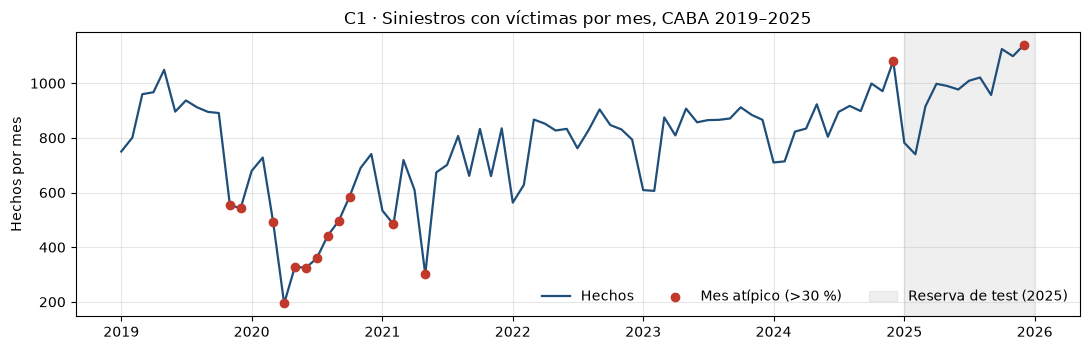

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.6))
x = mens["mes"].dt.to_timestamp()
ax.plot(x, mens["hechos"], color="#1f4e79", lw=1.6, label="Hechos")
ax.scatter(x[mens["atipico"]], mens.loc[mens["atipico"], "hechos"], color="#c0392b", zorder=3, label="Mes atípico (>30 %)")
ax.axvspan(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END), color="#999", alpha=.15, label="Reserva de test (2025)")
ax.set_ylabel("Hechos por mes"); ax.set_title("C1 · Siniestros con víctimas por mes, CABA 2019–2025")
ax.legend(frameon=False, ncol=3, loc="lower right"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG / "c01_hechos_mensuales.png", dpi=150); plt.show()

## 2. Duplicados y relación hechos-víctimas

Se concilian hechos y víctimas por separado antes de unirlos: unicidad de la clave, huérfanos, cardinalidad, consistencia de los conteos y duplicados probables. Un hecho se considera **posible duplicado** si comparte fecha, hora y coordenadas (redondeadas a 5 decimales, unos 1 m) con otro hecho de distinto `id_siniestro`.

In [5]:
c2 = {}
c2["id_hecho_unico"] = bool(h["id_siniestro"].is_unique)
c2["filas_hecho_identicas"] = int(hechos.duplicated().sum())
c2["victimas_sin_id"] = int(v["id_siniestro"].isna().sum())
c2["victimas_huerfanas"] = int((~v["id_siniestro"].dropna().isin(h["id_siniestro"])).sum())
c2["hechos_sin_victima"] = int((~h["id_siniestro"].isin(v["id_siniestro"])).sum())
filas = v.groupby("id_siniestro").size()
c2["conteo_hecho_igual_filas_victima"] = float((h.set_index("id_siniestro")["n_victimas"] == filas.reindex(h["id_siniestro"]).values).mean())
c2["victimas_por_hecho_dist"] = filas.value_counts().sort_index().head(6).to_dict()
c2["filas_victima_identicas"] = int(victimas.duplicated().sum())
dup_v = victimas[victimas.duplicated(keep=False)]
c2["filas_en_grupos_identicos_con_sexo_o_edad_SD"] = f"{int(dup_v[['sexo_victima', 'edad_victima']].eq('SD').any(axis=1).sum())} de {len(dup_v)}"
# gravedad: hecho vs víctimas
gmax = v.assign(o=v["gravedad"].map({"LEVE": 1, "GRAVE": 2, "MORTAL": 3})).groupby("id_siniestro")["o"].max().map({1: "LEVE", 2: "GRAVE", 3: "MORTAL"})
c2["gravedad_hecho_igual_max_victima"] = float((h.set_index("id_siniestro")["gravedad_siniestro"] == gmax.reindex(h["id_siniestro"]).values).mean())
c2["HC_igual_MORTAL"] = bool(((h["id_siniestro"].str[:2] == "HC") == (h["gravedad_siniestro"] == "MORTAL")).all())
# posibles duplicados por fecha-hora-lugar
key = h.dropna(subset=["lat", "lon"]).assign(la=lambda d: d["lat"].round(5), lo=lambda d: d["lon"].round(5))
grp = key.groupby(["fecha_siniestro", "hora_siniestro", "la", "lo"])["id_siniestro"].transform("size")
c2["hechos_en_grupos_misma_fecha_hora_lugar"] = int((grp > 1).sum())
c2["grupos_misma_fecha_hora_lugar"] = int(key[grp > 1].groupby(["fecha_siniestro", "hora_siniestro", "la", "lo"]).ngroups)
METRICS["c2"] = c2
pd.Series(c2, dtype=object).to_frame("valor")

,valor
id_hecho_unico,True
filas_hecho_identicas,0
victimas_sin_id,4
victimas_huerfanas,0
hechos_sin_victima,0
conteo_hecho_igual_filas_victima,1.0
victimas_por_hecho_dist,"{1: 59053, 2: 5294, 3: 911, 4: 303, 5: 135, 6:..."
filas_victima_identicas,1439
filas_en_grupos_identicos_con_sexo_o_edad_SD,1671 de 2620
gravedad_hecho_igual_max_victima,0.999529


**Lectura.** Si la clave es única, no hay huérfanos y los conteos coinciden con las filas, la relación hecho-víctima es **1:N íntegra**. Las filas idénticas de víctimas pueden ser personas distintas con los mismos atributos, a menudo con sexo o edad `SD`, porque no hay identificador de víctima: **no se eliminan**. Los grupos con igual fecha, hora y lugar son posibles duplicados (por ejemplo, un sumario por cada víctima). Su peso se informa y se analiza su efecto en el control 10. El ETL los conservará con una marca.

## 3. Coordenadas faltantes e inválidas

Se controla: (a) faltantes y valores no numéricos; (b) puntos fuera del polígono de CABA, que es la unión de comunas; (c) puntos a menos de 25 m de un límite de barrio; (d) coordenadas repetidas, que pueden indicar geocodificación por defecto; y (e) concordancia entre lat/lon (WGS84) y `geocodificacion_plana`. El CRS plano se identificó probando candidatos: con Gauss-Krüger BA y datum Campo Inchauspe, la mediana de la distancia es de centímetros.

In [6]:
c3 = {}
c3["sin_coordenada"] = int(h["lat"].isna().sum()); c3["sin_coordenada_pct"] = round(h["lat"].isna().mean() * 100, 2)
c3["no_numericas_SD"] = int((h["latitud_siniestro"].notna() & h["lat"].isna()).sum())
pts = gpd.GeoDataFrame(h[h["lat"].notna()][["id_siniestro"]], geometry=gpd.points_from_xy(h.loc[h["lat"].notna(), "lon"], h.loc[h["lat"].notna(), "lat"]), crs=4326)
caba = comunas.union_all()
c3["fuera_de_CABA"] = int((~pts.within(caba)).sum())
caba_m = comunas.to_crs(CRS_CABA).union_all()
d_out = pts.to_crs(CRS_CABA).loc[~pts.within(caba)].distance(caba_m)
c3["fuera_de_CABA_distancia_m"] = {"mediana": round(float(d_out.median()), 1), "p95": round(float(d_out.quantile(.95)), 1), "max": round(float(d_out.max()), 1),
                                   "a_menos_de_200m": int((d_out <= 200).sum())}
# distancia a límites de barrio (en metros)
pts_m = pts.to_crs(CRS_CABA); bord = barrios.to_crs(CRS_CABA).boundary.union_all()
dist_b = pts_m.distance(bord)
c3["a_menos_de_25m_de_limite_barrio"] = int((dist_b < 25).sum())
# coordenadas repetidas
rep = h.dropna(subset=["lat"]).groupby(["lat", "lon"]).size().sort_values(ascending=False)
c3["coordenada_mas_repetida_n"] = int(rep.iloc[0]); c3["coordenadas_con_mas_de_50_hechos"] = int((rep > 50).sum())
# faltantes por año y gravedad
falt = h.assign(sin_coord=h["lat"].isna()).pivot_table(index="anio", columns="gravedad_siniestro", values="sin_coord", aggfunc="mean").round(3)
falt.to_csv(TAB / "c03_sin_coordenada_por_anio_gravedad.csv")
c3["sin_coordenada_por_gravedad"] = h["lat"].isna().groupby(h["gravedad_siniestro"]).mean().round(3).to_dict()
# concordancia con coordenadas planas
xy = h["geocodificacion_plana"].str.extract(r"^POINT ?\((-?\d+(?:\.\d+)?) (-?\d+(?:\.\d+)?)\)$").astype(float)
ok = h["lat"].notna() & xy[0].notna() & (xy[0] > 1000)
plana = gpd.GeoSeries(gpd.points_from_xy(xy.loc[ok, 0], xy.loc[ok, 1]), crs=CRS_CABA, index=h.index[ok])
geo = gpd.GeoSeries(gpd.points_from_xy(h.loc[ok, "lon"], h.loc[ok, "lat"]), crs=4326, index=h.index[ok]).to_crs(CRS_CABA)
dpl = plana.distance(geo)
c3["plana_comparables"] = int(ok.sum()); c3["plana_mediana_m"] = round(float(dpl.median()), 2)
c3["plana_discrepancia_mayor_500m"] = int((dpl > 500).sum())
c3["plana_mal_formada_o_otra_escala"] = int((h["geocodificacion_plana"].notna() & ~ok & h["lat"].notna()).sum())
c3["plana_discrepancia_500m_por_anio"] = h.loc[dpl[dpl > 500].index, "anio"].value_counts().sort_index().to_dict()
METRICS["c3"] = c3
display(pd.Series(c3, dtype=object).to_frame("valor")); display(falt)

,valor
sin_coordenada,3031
sin_coordenada_pct,4.61
no_numericas_SD,653
fuera_de_CABA,286
fuera_de_CABA_distancia_m,"{'mediana': 7.7, 'p95': 46.9, 'max': 159.1, 'a..."
a_menos_de_25m_de_limite_barrio,13278
coordenada_mas_repetida_n,60
coordenadas_con_mas_de_50_hechos,2
sin_coordenada_por_gravedad,"{'GRAVE': 0.151, 'LEVE': 0.042, 'MORTAL': 0.004}"
plana_comparables,58761


gravedad_siniestro,GRAVE,LEVE,MORTAL
anio,,,
2019,0.059,0.052,0.000
2020,0.091,0.032,0.025
2021,0.277,0.056,0.010
2022,0.192,0.033,0.000
2023,0.126,0.025,0.000
2024,0.174,0.036,0.000
2025,0.114,0.052,0.000


**Lectura.** Todas las coordenadas numéricas caen dentro de CABA. El problema principal es el **faltante**, que **no es aleatorio por gravedad**. Las discrepancias de más de 500 m entre lat/lon y la coordenada plana se concentran en algunos años y señalan una incertidumbre de geocodificación. En el control 4 se mide cuántas cambian de barrio. Se usará lat/lon (WGS84) como coordenada principal, porque es completa y está dentro de CABA, y la coordenada plana como control.

## 4. Consistencia de barrios y comunas

La fuente no trae barrio. Se asignan barrio y comuna con una **unión espacial punto-en-polígono** (`within`) y se comparan con la comuna informada por la fuente. También se mide la sensibilidad de la asignación de barrio cuando se usa la coordenada plana en lugar de lat/lon.

In [7]:
c4 = {}
bj = gpd.sjoin(pts, barrios[["nombre", "comuna", "geometry"]], how="left", predicate="within")
c4["puntos"] = len(pts); c4["filas_tras_union"] = len(bj)
c4["coincidencias_multiples"] = int(bj.index.duplicated().sum())
c4["sin_barrio_within"] = int(bj["nombre"].isna().sum())
bj = bj[~bj.index.duplicated()]
# Puntos fuera del polígono (sobre avenidas límite o la costa): barrio más cercano a ≤ 200 m
miss = bj["nombre"].isna()
near = gpd.sjoin_nearest(pts.loc[miss].to_crs(CRS_CABA), barrios.to_crs(CRS_CABA)[["nombre", "comuna", "geometry"]],
                         how="left", max_distance=200, distance_col="dist_m")
near = near[~near.index.duplicated()]
c4["asignados_por_cercania_200m"] = int(near["nombre"].notna().sum())
bj.loc[near.index, ["nombre", "comuna"]] = near[["nombre", "comuna"]].values
h["metodo_asignacion"] = pd.Series("within", index=bj.index).where(~miss, "nearest_200m").reindex(h.index)
h["barrio"] = bj["nombre"].reindex(h.index)
h["comuna_geo"] = pd.to_numeric(bj["comuna"].reindex(h.index), errors="coerce").astype("Int64")
both = h["comuna_geo"].notna() & h["comuna_fuente"].notna()
c4["comuna_fuente_igual_geo"] = round(float((h.loc[both, "comuna_geo"] == h.loc[both, "comuna_fuente"]).mean()), 4)
c4["comuna_discordante_n"] = int((h.loc[both, "comuna_geo"] != h.loc[both, "comuna_fuente"]).sum())
disc = both & (h["comuna_geo"] != h["comuna_fuente"])
c4["discordantes_a_menos_de_100m_de_limite"] = int((dist_b.reindex(h.index[disc]) < 100).sum())
c4["sin_coord_con_comuna_fuente"] = int((h["lat"].isna() & h["comuna_fuente"].notna()).sum())
c4["sin_coord_ni_comuna"] = int((h["lat"].isna() & h["comuna_fuente"].isna()).sum())
# sensibilidad a la coordenada plana
bpl = gpd.sjoin(gpd.GeoDataFrame(geometry=plana.to_crs(4326)), barrios[["nombre", "geometry"]], how="left", predicate="within")
bpl = bpl[~bpl.index.duplicated()]["nombre"]
cmp_ = pd.concat([h.loc[bpl.index, "barrio"], bpl], axis=1, keys=["latlon", "plana"]).dropna()
c4["barrio_distinto_con_plana"] = int((cmp_["latlon"] != cmp_["plana"]).sum())
c4["barrio_distinto_con_plana_pct"] = round(float((cmp_["latlon"] != cmp_["plana"]).mean()) * 100, 2)
# cobertura asignable por escala
c4["asignables_barrio_pct"] = round(float(h["barrio"].notna().mean()) * 100, 2)
h["comuna_final"] = h["comuna_geo"].fillna(h["comuna_fuente"])
c4["asignables_comuna_pct"] = round(float(h["comuna_final"].notna().mean()) * 100, 2)
METRICS["c4"] = c4
pd.Series(c4, dtype=object).to_frame("valor")

,valor
puntos,62787
filas_tras_union,62787
coincidencias_multiples,0
sin_barrio_within,287
asignados_por_cercania_200m,287
comuna_fuente_igual_geo,0.9624
comuna_discordante_n,2329
discordantes_a_menos_de_100m_de_limite,2296
sin_coord_con_comuna_fuente,371
sin_coord_ni_comuna,2660


**Regla de asignación propuesta para el ETL (Paso 04):**
- **Barrio:** unión espacial lat/lon `within` con la capa oficial F04.
- **Comuna:** se deriva del barrio. Si no hay coordenada, se usa la comuna informada por la fuente.
- **Hechos sin coordenada ni comuna:** se excluyen del panel zonal con una marca de motivo. Se conservan en los totales de la ciudad.
- **Discordancias de comuna:** prevalece la geometría, y la discordancia se registra.

## 5. Cambios metodológicos entre años

Se compara, año por año, la completitud de cada campo y la composición de las categorías. Se investiga si la caída de noviembre y diciembre de 2019 es **homogénea entre comunas**, lo que sugeriría un cambio de registro, o **localizada**.

In [8]:
campos = {"coordenada": h["lat"].isna(), "comuna": h["comuna_fuente"].isna(),
          "tipo_de_via": h["tipo_de_via_siniestro"].isna() | h["tipo_de_via_siniestro"].eq("SD"),
          "modo_victima": h["modo_desplazamiento_victima"].isna() | h["modo_desplazamiento_victima"].eq("SD"),
          "contraparte": h["contraparte_siniestro"].isna() | h["contraparte_siniestro"].str.upper().eq("SD"),
          "hora": h["hora_siniestro"].isna(), "n_total_victimas_SD": h["numero_total_de_victimas"].eq("SD")}
falt_anio = pd.DataFrame({k: s.groupby(h["anio"]).mean() for k, s in campos.items()}).round(3)
falt_anio.to_csv(TAB / "c05_faltantes_por_anio.csv"); display(falt_anio)
comp = pd.crosstab(h["anio"], h["gravedad_siniestro"], normalize="index").round(4)
modo = pd.crosstab(h["anio"], h["modo_desplazamiento_victima"].str.upper(), normalize="index").round(3)
modo = modo[[c for c in ["MOTO", "PEATON", "BICICLETA", "AUTO", "TRANSPORTE PUBLICO", "SD"] if c in modo.columns]]
comp.to_csv(TAB / "c05_gravedad_por_anio.csv"); modo.to_csv(TAB / "c05_modo_victima_por_anio.csv")
display(comp); display(modo)

,coordenada,comuna,tipo_de_via,modo_victima,contraparte,hora,n_total_victimas_SD
anio,,,,,,,
2019,0.052,0.059,0.951,0.097,0.103,0.000,0.000
2020,0.033,0.048,0.047,0.217,0.372,0.000,0.000
2021,0.066,0.071,0.076,0.295,0.361,0.001,0.000
2022,0.042,0.048,0.119,0.104,0.158,0.001,0.000
2023,0.029,0.036,0.035,0.118,0.225,0.002,0.000
2024,0.043,0.071,0.020,0.265,0.268,0.004,0.000
2025,0.056,0.046,0.027,0.116,0.117,0.000,0.279


gravedad_siniestro,GRAVE,LEVE,MORTAL
anio,,,
2019,0.0367,0.9531,0.0101
2020,0.0236,0.9634,0.0130
2021,0.0458,0.9419,0.0123
2022,0.0547,0.9340,0.0112
2023,0.0359,0.9537,0.0105
2024,0.0488,0.9408,0.0104
2025,0.0585,0.9339,0.0077


modo_desplazamiento_victima,MOTO,PEATON,BICICLETA,AUTO,TRANSPORTE PUBLICO,SD
anio,,,,,,
2019,0.390,0.163,0.100,0.120,0.060,0.097
2020,0.349,0.127,0.129,0.100,0.032,0.217
2021,0.311,0.118,0.122,0.082,0.040,0.295
2022,0.394,0.162,0.115,0.119,0.066,0.104
2023,0.405,0.148,0.103,0.133,0.059,0.118
2024,0.333,0.124,0.090,0.086,0.046,0.265
2025,0.404,0.148,0.108,0.106,0.070,0.116


In [9]:
# ¿La caída de nov-dic 2019 es homogénea entre comunas?
def share(df):
    return df["comuna_final"].value_counts(normalize=True).sort_index()
a = h[(h["anio"] == 2019) & (h["fecha"].dt.month <= 10)]; b = h[(h["anio"] == 2019) & (h["fecha"].dt.month >= 11)]
ref_ = h[h["anio"].isin([2022, 2023]) & (h["fecha"].dt.month >= 11)]
tab = pd.concat([share(a), share(b), share(ref_)], axis=1, keys=["2019_ene-oct", "2019_nov-dic", "2022-23_nov-dic"]).round(3)
chi = stats.chi2_contingency(pd.concat([a["comuna_final"].value_counts(), b["comuna_final"].value_counts()], axis=1).fillna(0).to_numpy(dtype=float))
ratio_nd = len(b) / 2 / (len(a) / 10)
METRICS["c5"] = {"ratio_mensual_nov_dic_vs_ene_oct_2019": round(ratio_nd, 3),
                 "chi2_p_composicion_comunal_2019": float(chi[1]),
                 "max_dif_participacion_comunal_pp": round(float((tab["2019_nov-dic"] - tab["2019_ene-oct"]).abs().max() * 100), 2),
                 "tipo_de_via_faltante_2019": float(falt_anio.loc[2019, "tipo_de_via"])}
print(METRICS["c5"]); tab

{'ratio_mensual_nov_dic_vs_ene_oct_2019': 0.606, 'chi2_p_composicion_comunal_2019': 0.00042193210888188124, 'max_dif_participacion_comunal_pp': 2.6, 'tipo_de_via_faltante_2019': 0.951}


,2019_ene-oct,2019_nov-dic,2022-23_nov-dic
comuna_final,,,
1,0.116,0.115,0.115
2,0.041,0.054,0.04
3,0.072,0.087,0.082
4,0.076,0.079,0.066
5,0.059,0.05,0.045
6,0.041,0.038,0.04
7,0.063,0.07,0.075
8,0.048,0.065,0.049
9,0.072,0.098,0.071


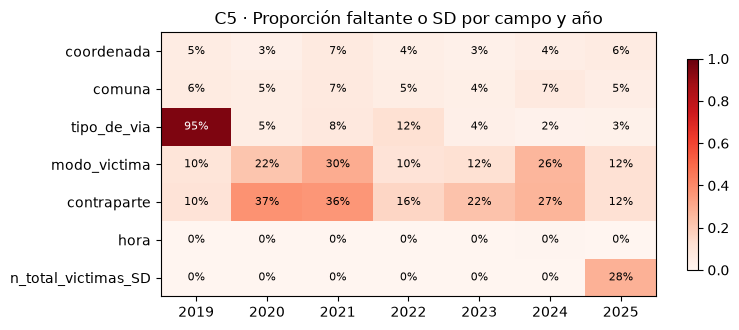

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(falt_anio.T.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(falt_anio.index)), falt_anio.index); ax.set_yticks(range(len(falt_anio.columns)), falt_anio.columns)
for i in range(falt_anio.shape[1]):
    for j in range(falt_anio.shape[0]):
        val = falt_anio.T.values[i, j]; ax.text(j, i, f"{val:.0%}", ha="center", va="center", fontsize=8, color="white" if val > .5 else "black")
ax.set_title("C5 · Proporción faltante o SD por campo y año"); fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig(FIG / "c05_faltantes_por_anio.png", dpi=150); plt.show()

**Lectura.** `tipo_de_via` no es comparable en 2019, y `modo_victima` y `contraparte` tienen faltantes variables entre años. Por eso **no sirven como variables de composición sin un tratamiento explícito**. La caída de noviembre y diciembre de 2019 se evalúa con la participación por comuna. Si la composición territorial casi no cambia mientras el nivel cae, la hipótesis más compatible es un **cambio de registro a nivel ciudad**, no un fenómeno local. Esto afecta los rezagos y la línea de base del primer año y se trata en la matriz de decisión.

## 6. Distribución territorial de las observaciones (período de desarrollo)

Se analizan conteos, densidad por km² y concentración: participación del 10 % y del 20 % superior, y coeficiente de Gini. La **persistencia** se mide como la correlación de Spearman entre los rankings de años consecutivos. Todo se calcula solo con 2019–2024.

In [11]:
dev = h[h["dev"]]
area_b = barrios.to_crs(CRS_CABA).set_index("nombre").area / 1e6
area_c = comunas.to_crs(CRS_CABA).assign(comuna=lambda d: d["comuna"].astype(int)).set_index("comuna").area / 1e6
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))
def conc(counts, area):
    s = counts.reindex(area.index).fillna(0).sort_values(ascending=False)
    n = len(s); return {"unidades": n, "top10pct_share": round(s.iloc[: max(1, round(n * .1))].sum() / s.sum(), 3),
                        "top20pct_share": round(s.iloc[: max(1, round(n * .2))].sum() / s.sum(), 3),
                        "share_esperado_top20_si_prop_area": round(area.reindex(s.index[: max(1, round(n * .2))]).sum() / area.sum(), 3),
                        "gini": round(gini(s.values), 3), "cv": round(s.std() / s.mean(), 3)}
cnt_b = dev["barrio"].value_counts(); cnt_c = dev["comuna_final"].dropna().astype(int).value_counts()
c6 = {"barrio": conc(cnt_b, area_b), "comuna": conc(cnt_c, area_c)}
def persist(df, unit, index):
    t = df.pivot_table(index=unit, columns="anio", values="id_siniestro", aggfunc="size").reindex(index).fillna(0)
    return {f"{a}-{b}": round(stats.spearmanr(t[a], t[b]).statistic, 3) for a, b in zip(t.columns[:-1], t.columns[1:])}
c6["barrio"]["spearman_anual"] = persist(dev, "barrio", area_b.index)
tm = dev.pivot_table(index="barrio", columns="mes", values="id_siniestro", aggfunc="size").reindex(area_b.index).fillna(0)
sm = [stats.spearmanr(tm.iloc[:, i], tm.iloc[:, i + 1]).statistic for i in range(tm.shape[1] - 1)]
c6["barrio"]["spearman_mensual_consecutivo"] = {"mediana": round(float(np.median(sm)), 3), "min": round(float(np.min(sm)), 3), "max": round(float(np.max(sm)), 3)}
c6["comuna"]["spearman_anual"] = persist(dev.assign(c=dev["comuna_final"]).dropna(subset=["c"]).assign(c=lambda d: d["c"].astype(int)), "c", area_c.index)
METRICS["c6"] = c6
tb = pd.DataFrame({"hechos_2019_2024": cnt_b.reindex(area_b.index).fillna(0).astype(int), "area_km2": area_b.round(2)})
tb["hechos_por_km2_anual"] = (tb["hechos_2019_2024"] / 6 / tb["area_km2"]).round(1)
tb.sort_values("hechos_2019_2024", ascending=False).to_csv(TAB / "c06_barrios_conteo_densidad.csv")
display(pd.DataFrame({k: {kk: vv for kk, vv in d.items() if not kk.startswith("spearman")} for k, d in c6.items()}))
print("Spearman mensual consecutivo (barrio):", c6["barrio"]["spearman_mensual_consecutivo"])
display(pd.DataFrame({k: d["spearman_anual"] for k, d in c6.items()}))

,barrio,comuna
unidades,48.000,15.000
top10pct_share,0.262,0.197
top20pct_share,0.424,0.272
share_esperado_top20_si_prop_area,0.347,0.196
gini,0.356,0.140
cv,0.698,0.284


Spearman mensual consecutivo (barrio): {'mediana': 0.824, 'min': 0.547, 'max': 0.887}


,barrio,comuna
2019-2020,0.958,0.896
2020-2021,0.974,0.854
2021-2022,0.982,0.932
2022-2023,0.969,0.947
2023-2024,0.968,0.953


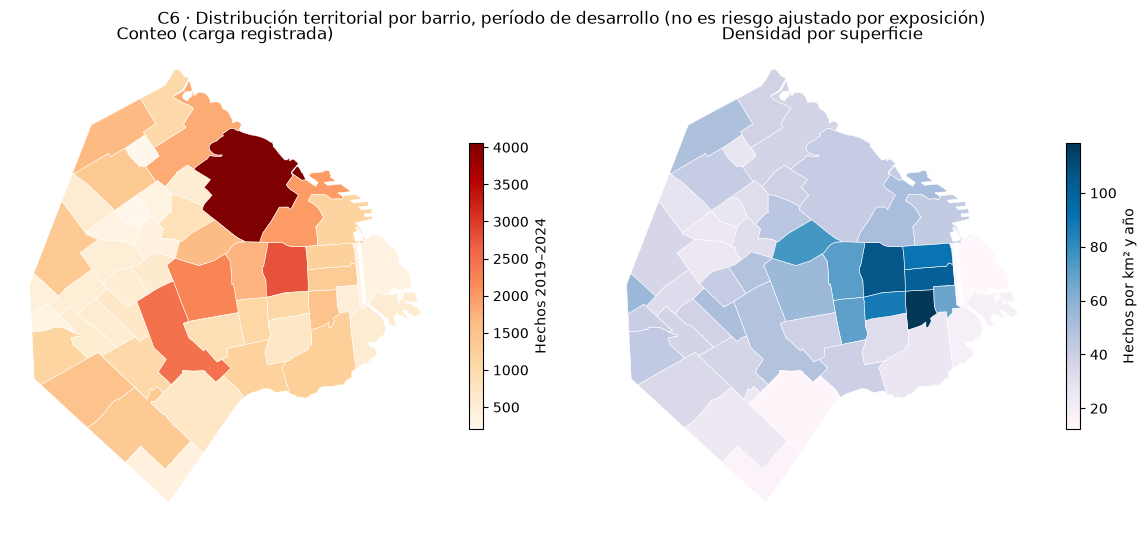

In [12]:
gb = barrios.merge(tb.reset_index().rename(columns={"index": "nombre"}), on="nombre", how="left")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
gb.plot(column="hechos_2019_2024", cmap="OrRd", legend=True, ax=axes[0], edgecolor="white", lw=.4, legend_kwds={"shrink": .6, "label": "Hechos 2019–2024"})
gb.plot(column="hechos_por_km2_anual", cmap="PuBu", legend=True, ax=axes[1], edgecolor="white", lw=.4, legend_kwds={"shrink": .6, "label": "Hechos por km² y año"})
for ax, t in zip(axes, ["Conteo (carga registrada)", "Densidad por superficie"]):
    ax.set_axis_off(); ax.set_title(t)
fig.suptitle("C6 · Distribución territorial por barrio, período de desarrollo (no es riesgo ajustado por exposición)")
fig.tight_layout(); fig.savefig(FIG / "c06_mapa_barrios.png", dpi=150); plt.show()

## 7. Proporción de unidades sin siniestros (*zero inflation*)

Se construyen **paneles completos** zona × período (los ceros son explícitos) para el período de desarrollo y para tres variables objetivo candidatas:
- **Y1:** hechos;
- **Y2:** víctimas;
- **Y3:** hechos KSI (graves o mortales).

Se comparan cuatro escalas del plan, más grillas de referencia de 1 km y 500 m para decidir si conviene una grilla. Para cada caso se informan la proporción de ceros, la media, la varianza, el índice de dispersión (varianza/media) y la **proporción de ceros esperada bajo un modelo Poisson con la media de cada unidad**. Un exceso de ceros respecto de esa referencia indica *zero inflation* propiamente dicha.

In [13]:
def make_grid(size_m):
    b = comunas.to_crs(CRS_CABA); minx, miny, maxx, maxy = b.total_bounds
    xs = np.arange(minx, maxx + size_m, size_m); ys = np.arange(miny, maxy + size_m, size_m)
    cells = [shapely.box(x0, y0, x0 + size_m, y0 + size_m) for x0 in xs for y0 in ys]
    g = gpd.GeoDataFrame({"celda": range(len(cells))}, geometry=cells, crs=CRS_CABA)
    return g[g.intersects(b.union_all())].reset_index(drop=True)
grids = {}
for size in (1000, 500):
    g = make_grid(size); grids[size] = g
    j = gpd.sjoin(pts_m, g, how="left", predicate="within")
    j = j[~j.index.duplicated()]
    h[f"grid{size}"] = j["celda"].reindex(h.index)

dev = h[h["dev"]].copy()
units = {"barrio": list(area_b.index), "comuna": list(area_c.index),
         "grid1000": list(grids[1000]["celda"]), "grid500": list(grids[500]["celda"])}
dev["comuna"] = dev["comuna_final"].astype("Int64")
periods = {"mes": pd.period_range(DEV_START, DEV_END, freq="M"), "trimestre": pd.period_range(DEV_START, DEV_END, freq="Q")}

def panel(unit, per, target):
    d = dev.dropna(subset=[unit])
    val = {"Y1_hechos": d.assign(y=1), "Y2_victimas": d.assign(y=d["n_victimas"]), "Y3_ksi": d.assign(y=d["ksi"].astype(int))}[target]
    idx = pd.MultiIndex.from_product([units[unit], periods[per]], names=[unit, per])
    return val.groupby([unit, per])["y"].sum().reindex(idx, fill_value=0).rename("y").reset_index()

rows = []
PANELS = {}
for unit in units:
    for per in periods:
        for tgt in ["Y1_hechos", "Y2_victimas", "Y3_ksi"]:
            p = panel(unit, per, tgt); PANELS[(unit, per, tgt)] = p
            y = p["y"].astype(float); mu_u = p.groupby(unit)["y"].transform("mean")
            rows.append({"unidad": unit, "periodo": per, "objetivo": tgt, "n_unidades": len(units[unit]),
                         "n_periodos": len(periods[per]), "n_obs": len(p), "media": round(y.mean(), 3),
                         "mediana": float(y.median()), "var": round(y.var(), 2),
                         "dispersion_var_media": round(y.var() / y.mean(), 2) if y.mean() > 0 else np.nan,
                         "prop_ceros": round((y == 0).mean(), 3),
                         "prop_ceros_poisson_esperada": round(float(np.exp(-mu_u).mean()), 3),
                         "unidades_siempre_cero": int((p.groupby(unit)["y"].sum() == 0).sum())})
zi = pd.DataFrame(rows); zi.to_csv(TAB / "c07_zero_inflation_por_escala.csv", index=False)
METRICS["c7"] = zi.to_dict(orient="records")
zi.pivot_table(index=["unidad", "periodo"], columns="objetivo", values=["prop_ceros", "prop_ceros_poisson_esperada", "media", "dispersion_var_media"]).round(3)

dispersion_var_media                        media                    prop_ceros                    prop_ceros_poisson_esperada              \
objetivo                      Y1_hechos Y2_victimas Y3_ksi Y1_hechos Y2_victimas Y3_ksi  Y1_hechos Y2_victimas Y3_ksi                   Y1_hechos Y2_victimas   
unidad   periodo                                                                                                                                                
barrio   mes                       9.75       11.37   1.53    14.956      17.173  0.722      0.012       0.012  0.555                       0.003       0.002   
         trimestre                26.22       29.90   2.53    44.868      51.519  2.166      0.000       0.000  0.248                       0.000       0.000   
comuna   mes                       8.13        9.94   1.50    48.056      55.194  2.322      0.000       0.000  0.163                       0.000       0.000   
         trimestre                20.29       24.20   2.56   144.167     165.581  6.967      0.000       0.000  0.017                       0.000       0.000   
grid1000 mes                       3.28        3.98   1.10     2.942       3.378  0.142      0.256       0.256  0.873                       0.236       0.211   
         trimestre                 7.57        8.74   1.36     8.827      10.135  0.426      0.150       0.150  0.694                       0.139       0.131   
grid500  mes                       1.77        2.29   1.05     0.790       0.907  0.038      0.560       0.560  0.963                       0.547       0.511   
         trimestre                 3.19        3.91   1.14     2.369       2.720  0.114      0.307       0.307  0.898                       0.291       0.265   

                           
objetivo           Y3_ksi  
unidad   periodo           
barrio   mes        0.540  
         trimestre  0.218  
comuna   mes        0.130  
         trimestre  0.006  
grid1000 mes        0.873  
         trimestre  0.686  
grid500  mes        0.963  
         trimestre  0.898

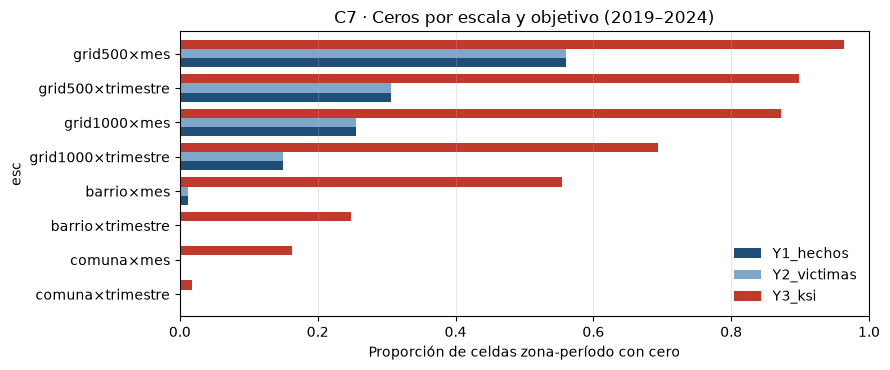

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
lab = zi.assign(esc=zi["unidad"] + "×" + zi["periodo"]).pivot(index="esc", columns="objetivo", values="prop_ceros")
lab = lab.loc[["comuna×trimestre", "comuna×mes", "barrio×trimestre", "barrio×mes", "grid1000×trimestre", "grid1000×mes", "grid500×trimestre", "grid500×mes"]]
lab.plot.barh(ax=ax, color=["#1f4e79", "#7fa7c9", "#c0392b"], width=.8)
ax.set_xlabel("Proporción de celdas zona-período con cero"); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=.3)
ax.set_title("C7 · Ceros por escala y objetivo (2019–2024)"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "c07_ceros_por_escala.png", dpi=150); plt.show()

## 8. Desbalance de las variables objetivo candidatas

**Regresión.** Se analizan la distribución, la sobredispersión y el ajuste Poisson frente a binomial negativa (NB2) por momentos.

**Clasificación.** Se comparan tres definiciones de "concentración en el período siguiente". Sus umbrales se calculan solo con 2019–2024:
- **C-a, umbral absoluto:** `y > P75` de la distribución conjunta zona-período del período de desarrollo. La prevalencia puede variar entre años según el nivel general.
- **C-b, umbral relativo por período:** la zona está entre las K = ⌈20 % de las unidades⌉ con más hechos de su período (10 de 48 barrios; 3 de 15 comunas). Hay **exactamente K positivos por período**. Los empates en el corte se resuelven con la regla explícita de la sección 8.1. La prevalencia es fija y evalúa el ordenamiento, que es la decisión top-K.
- **C-c, ocurrencia de KSI:** al menos un hecho grave o mortal.

Se informan la prevalencia global, la prevalencia por año y su estabilidad.

In [15]:
# Regla de etiquetado top-K con desempate explícito (se migrará a src/ en el Paso 06)
def top_k_labels(df, unit, per, k, seed=SEED, ycol="y"):
    # Exactamente k positivos por período. Orden: y descendente. Empates: clave pseudoaleatoria
    # uniforme generada con np.random.default_rng([seed, ordinal del período]) sobre las unidades
    # ordenadas por nombre o id. Es reproducible, neutral (no favorece siempre a las mismas unidades)
    # y no usa información del historial ni de los predictores.
    out = pd.Series(False, index=df.index)
    for prd, g in df.groupby(per, sort=False):
        g = g.sort_values(unit)
        key = np.random.default_rng([seed, int(prd.ordinal)]).random(len(g))
        order = np.lexsort((key, -g[ycol].to_numpy(dtype=float)))
        out.loc[g.index[order[:k]]] = True
    return out

def inclusion_prob(scores, k):
    # Probabilidad de que cada unidad quede en el top-k si los empates del corte se resuelven al azar
    s = np.asarray(scores, float); c = np.sort(s)[::-1][k - 1]
    above, tied = (s > c).sum(), (s == c).sum()
    return np.where(s > c, 1.0, np.where(s == c, (k - above) / tied, 0.0))
K_SHARE = .2

In [16]:
rows = []
for unit in ["barrio", "comuna"]:
    for per in ["mes", "trimestre"]:
        p1 = PANELS[(unit, per, "Y1_hechos")].copy(); p3 = PANELS[(unit, per, "Y3_ksi")]
        p1["anio"] = p1[per].dt.year
        thr = p1["y"].quantile(.75)
        p1["Ca"] = p1["y"] > thr
        p1["Cb"] = top_k_labels(p1, unit, per, int(np.ceil(len(units[unit]) * K_SHARE)))
        p1["Cc"] = p3["y"].values > 0
        for k in ["Ca", "Cb", "Cc"]:
            by_year = p1.groupby("anio")[k].mean()
            rows.append({"unidad": unit, "periodo": per, "definicion": k, "umbral": thr if k == "Ca" else None,
                         "prevalencia": round(p1[k].mean(), 3), "prev_min_anual": round(by_year.min(), 3),
                         "prev_max_anual": round(by_year.max(), 3), "positivos": int(p1[k].sum())})
imb = pd.DataFrame(rows); imb.to_csv(TAB / "c08_prevalencia_clasificacion.csv", index=False)
METRICS["c8_clasificacion"] = imb.to_dict(orient="records")
imb

,unidad,periodo,definicion,umbral,prevalencia,prev_min_anual,prev_max_anual,positivos
0,barrio,mes,Ca,20.0,0.249,0.118,0.316,860
1,barrio,mes,Cb,NaN,0.208,0.208,0.208,720
2,barrio,mes,Cc,NaN,0.445,0.276,0.528,1538
3,barrio,trimestre,Ca,60.0,0.245,0.099,0.328,282
4,barrio,trimestre,Cb,NaN,0.208,0.208,0.208,240
5,barrio,trimestre,Cc,NaN,0.752,0.573,0.828,866
6,comuna,mes,Ca,60.0,0.235,0.050,0.361,254
7,comuna,mes,Cb,NaN,0.200,0.200,0.200,216
8,comuna,mes,Cc,NaN,0.837,0.617,0.939,904
9,comuna,trimestre,Ca,177.0,0.244,0.033,0.400,88


### 8.1 Empates en el corte del top-K (C-b)

Con conteos enteros, varios barrios pueden empatar en el puesto 10. Desempatar por el orden de las filas haría que una propiedad arbitraria del archivo decidiera qué barrio es positivo. Por eso se fija una **regla explícita** y se separan dos preguntas distintas.

**(a) Sensibilidad al desempate.** Se mantiene la definición de exactamente 10 positivos y solo cambia cómo se resuelven los empates en el corte.
- **R0 (regla principal):** clave pseudoaleatoria uniforme y reproducible (`SEED` = 20261110 y el ordinal del mes). Es neutral: no favorece sistemáticamente a ningún barrio ni usa el historial, que favorecería al baseline de persistencia.
- **500 semillas:** en cada repetición *r* se generan **una sola vez** las etiquetas y las selecciones, con la semilla del desempate de la repetición *r*. Ese mismo juego de etiquetas se aplica al ranking candidato y al baseline, sobre **los mismos meses**. Para cada *r* se calcula ΔP@10 = P@10(candidato) − P@10(baseline). Los percentiles 2,5 y 97,5 de ΔP@10 forman el **intervalo de sensibilidad al desempate** de la ventaja.
- **R-id:** desempate determinista por el `id` oficial del barrio.

**(b) Cambio en la definición de positivo.** Aquí se deja de exigir exactamente 10 positivos.
- **R-incl:** todos los empatados en el corte son positivos (más de 10 solo en los meses con empate; exactamente 10 en el resto).
- **R-excl-empates:** en los meses con empate entre los puestos 10 y 11, solo son positivos los que superan estrictamente el conteo del corte. En los meses sin empate quedan los 10 de siempre. R-incl y R-excl-empates difieren **solo** en los barrios empatados en el corte.
- **R-estricta** (antes llamada R-excl): positivo si y > conteo del décimo, **en todos los meses**. Excluye al décimo barrio, y a quienes comparten su conteo, **aunque su puesto sea inequívoco**. Mide un umbral estricto distinto, no el efecto del desempate. Se informa solo como cambio de definición.

Se ilustra con dos **rankings de referencia sin ajuste**, que no son modelos: la persistencia (y en t−1), usada como *baseline*, y la media de los 12 meses previos, usada como *candidato* ilustrativo. Se evalúan en 2020-01 a 2024-12, dentro del desarrollo y **sin usar 2025**. La **incertidumbre entre períodos** (variabilidad mes a mes de ΔP@10) es otra fuente de incertidumbre: se evaluará por separado en los Pasos 08 y 10, por ejemplo con un *bootstrap* por bloques de meses, y no se mezcla con este intervalo.

También se informa la **Precision@10 esperada invariante a empates**: E[|S∩P|]/10 = Σᵢ P(i∈S)·P(i∈P)/10, con los empates de S y de P resueltos al azar.

In [17]:
pb = PANELS[("barrio", "mes", "Y1_hechos")].copy().sort_values(["barrio", "mes"]).reset_index(drop=True)
K = 10
ids = barrios.set_index("nombre")["id"]
srt = lambda s: np.sort(s.to_numpy(dtype=float))[::-1]
cut = pd.DataFrame({"c10": pb.groupby("mes")["y"].apply(lambda s: srt(s)[K - 1]),
                    "c11": pb.groupby("mes")["y"].apply(lambda s: srt(s)[K])})
cut["empate_10_11"] = cut["c10"] == cut["c11"]
c10 = pb["mes"].map(cut["c10"]); tie_m = pb["mes"].map(cut["empate_10_11"]).astype(bool)
cut["empatados_en_corte"] = (pb["y"] == c10).groupby(pb["mes"]).sum()
cut["plazas_en_disputa"] = K - (pb["y"] > c10).groupby(pb["mes"]).sum()
cut.to_csv(TAB / "c08_empates_por_mes.csv")
L = {"R0": top_k_labels(pb, "barrio", "mes", K)}
pid = pb.assign(_id=pb["barrio"].map(ids))
L["R-id"] = pd.Series(False, index=pb.index)
for _, g in pid.groupby("mes"):
    L["R-id"].loc[g.sort_values(["y", "_id"], ascending=[False, True]).index[:K]] = True
L["R-incl"] = pb["y"] >= c10
L["R-excl-empates"] = (pb["y"] > c10) | ((pb["y"] == c10) & ~tie_m)
L["R-estricta"] = pb["y"] > c10
tipo = {"R0": "desempate", "R-id": "desempate", "R-incl": "definición (solo meses con empate)",
        "R-excl-empates": "definición (solo meses con empate)", "R-estricta": "definición (todos los meses)"}
tie_tab = pd.DataFrame({r: {"tipo": tipo[r],
                            "positivos_por_mes_min": int(l.groupby(pb["mes"]).sum().min()),
                            "positivos_por_mes_max": int(l.groupby(pb["mes"]).sum().max()),
                            "etiquetas_distintas_vs_R0": int((l != L["R0"]).sum()),
                            "distintas_vs_R0_en_meses_sin_empate": int(((l != L["R0"]) & ~tie_m).sum())} for r, l in L.items()}).T
tie_tab.to_csv(TAB / "c08_reglas_empate.csv")
amb = cut.loc[cut["empate_10_11"]]
METRICS["c8_empates"] = {"meses_con_empate_10_11": int(cut["empate_10_11"].sum()), "meses": len(cut),
                         "barrio_mes_empatados_en_corte_meses_con_empate": int(amb["empatados_en_corte"].sum()),
                         "plazas_en_disputa_total": int(amb["plazas_en_disputa"].sum()),
                         "empatados_por_mes_min_mediana_max": [int(amb["empatados_en_corte"].min()), float(amb["empatados_en_corte"].median()), int(amb["empatados_en_corte"].max())],
                         "R_estricta_excluye_en_meses_sin_empate": int((L["R0"] & ~L["R-estricta"] & ~tie_m).sum())}
print(METRICS["c8_empates"]); display(tie_tab)

{'meses_con_empate_10_11': 23, 'meses': 72, 'barrio_mes_empatados_en_corte_meses_con_empate': 69, 'plazas_en_disputa_total': 33, 'empatados_por_mes_min_mediana_max': [2, 3.0, 5], 'R_estricta_excluye_en_meses_sin_empate': 69}


,tipo,positivos_por_mes_min,positivos_por_mes_max,etiquetas_distintas_vs_R0,distintas_vs_R0_en_meses_sin_empate
R0,desempate,10,10,0,0
R-id,desempate,10,10,28,0
R-incl,definición (solo meses con empate),10,13,36,0
R-excl-empates,definición (solo meses con empate),7,10,33,0
R-estricta,definición (todos los meses),7,9,102,69


In [18]:
# Rankings de referencia (2020-01 a 2024-12; sin 2025)
pb["persist"] = pb.groupby("barrio")["y"].shift(1)
pb["media12"] = pb.groupby("barrio")["y"].transform(lambda s: s.shift(1).rolling(12, min_periods=12).mean())
ev = pb[pb["mes"] >= pd.Period("2020-01", "M")].copy()
n_meses_ev = ev["mes"].nunique()
CAND, BASE = "media12", "persist"

def p_at_k_by_month(ev, score, labels, seed_sel):
    sel = top_k_labels(ev, "barrio", "mes", K, seed=seed_sel, ycol=score)
    return (sel & labels.loc[ev.index]).groupby(ev["mes"]).sum() / K, labels.loc[ev.index].groupby(ev["mes"]).sum()

def expected_prec(ev, score):
    return float(np.mean([(inclusion_prob(g[score], K) * inclusion_prob(g["y"], K)).sum() / K for _, g in ev.groupby("mes")]))

# (b) Reglas de etiquetado fijas: mismas etiquetas y mismos meses para candidato y baseline
rows = []
for r, lab in L.items():
    pc, npos = p_at_k_by_month(ev, CAND, lab, SEED + 1); pbm, _ = p_at_k_by_month(ev, BASE, lab, SEED + 1)
    rows.append({"regla": r, "tipo": tipo[r], f"P@10_{CAND}": round(pc.mean(), 4), f"P@10_{BASE}": round(pbm.mean(), 4),
                 "dif_P@10": round(pc.mean() - pbm.mean(), 4),
                 f"recall_{CAND}": round((pc * K / npos).mean(), 4), f"recall_{BASE}": round((pbm * K / npos).mean(), 4)})
rows.append({"regla": "esperada_invariante", "tipo": "sin semilla", f"P@10_{CAND}": round(expected_prec(ev, CAND), 4),
             f"P@10_{BASE}": round(expected_prec(ev, BASE), 4), "dif_P@10": round(expected_prec(ev, CAND) - expected_prec(ev, BASE), 4)})
rules_tab = pd.DataFrame(rows)

# (a) 500 repeticiones: en cada una, etiquetas y selecciones comunes; diferencia pareada
sims = []
for sd in range(500):
    lab = top_k_labels(pb, "barrio", "mes", K, seed=SEED + 1000 + sd)
    pc, _ = p_at_k_by_month(ev, CAND, lab, SEED + 5000 + sd); pbm, _ = p_at_k_by_month(ev, BASE, lab, SEED + 5000 + sd)
    sims.append({"semilla": sd, f"P@10_{CAND}": pc.mean(), f"P@10_{BASE}": pbm.mean(), "dif_P@10": pc.mean() - pbm.mean()})
sims = pd.DataFrame(sims); sims.to_csv(TAB / "c08_semillas_diferencia_pareada.csv", index=False)
q = lambda s: {"p2.5": round(float(s.quantile(.025)), 4), "mediana": round(float(s.median()), 4), "p97.5": round(float(s.quantile(.975)), 4),
               "min": round(float(s.min()), 4), "max": round(float(s.max()), 4)}
seed_tab = pd.DataFrame({c: q(sims[c]) for c in [f"P@10_{CAND}", f"P@10_{BASE}", "dif_P@10"]}).T
# Referencia: dispersión entre meses de la diferencia (otra fuente de incertidumbre; no se mezcla)
pc0, _ = p_at_k_by_month(ev, CAND, L["R0"], SEED + 1); pb0, _ = p_at_k_by_month(ev, BASE, L["R0"], SEED + 1)
d_mes = pc0 - pb0
incl_excl = {r: float(rules_tab.set_index("regla").loc["R-incl", f"P@10_{r}"] - rules_tab.set_index("regla").loc["R-estricta", f"P@10_{r}"]) for r in [CAND, BASE]}
rules_tab.to_csv(TAB / "c08_sensibilidad_empates.csv", index=False); seed_tab.to_csv(TAB / "c08_intervalo_sensibilidad_desempate.csv")
METRICS["c8_sensibilidad_empates"] = {"meses_evaluados": int(n_meses_ev), "candidato": CAND, "baseline": BASE,
                                      "reglas": rules_tab.to_dict(orient="records"), "semillas_500": seed_tab.to_dict(orient="index"),
                                      "R_incl_menos_R_estricta": {k: round(v, 4) for k, v in incl_excl.items()},
                                      "dif_P@10_entre_meses_R0": {"media": round(float(d_mes.mean()), 4), "desvio": round(float(d_mes.std()), 4)}}
print("Meses evaluados:", n_meses_ev, "| R-incl − R-estricta:", METRICS["c8_sensibilidad_empates"]["R_incl_menos_R_estricta"])
print("Dispersión entre meses de ΔP@10 (R0; solo como referencia, no es el intervalo de desempate):", METRICS["c8_sensibilidad_empates"]["dif_P@10_entre_meses_R0"])
display(rules_tab); display(seed_tab)

Meses evaluados: 60 | R-incl − R-estricta: {'media12': 0.0934, 'persist': 0.0867}
Dispersión entre meses de ΔP@10 (R0; solo como referencia, no es el intervalo de desempate): {'media': 0.0633, 'desvio': 0.1193}


,regla,tipo,P@10_media12,P@10_persist,dif_P@10,recall_media12,recall_persist
0,R0,desempate,0.7500,0.6867,0.0633,0.7500,0.6867
1,R-id,desempate,0.7550,0.6900,0.0650,0.7550,0.6900
2,R-incl,definición (solo meses con empate),0.7717,0.7100,0.0617,0.7339,0.6751
3,R-excl-empates,definición (solo meses con empate),0.7283,0.6650,0.0633,0.7673,0.6986
4,R-estricta,definición (todos los meses),0.6783,0.6233,0.0550,0.7950,0.7284
5,esperada_invariante,sin semilla,0.7501,0.6816,0.0685,NaN,NaN


,p2.5,mediana,p97.5,min,max
P@10_media12,0.7450,0.7500,0.7567,0.7417,0.7583
P@10_persist,0.6733,0.6817,0.6900,0.6667,0.6933
dif_P@10,0.0600,0.0683,0.0767,0.0583,0.0833


**Lectura y regla adoptada.**
- **R0 es la regla principal.** Las 500 semillas aíslan el efecto del desempate porque mantienen la definición (diez positivos). El intervalo de sensibilidad de una ventaja es el percentil 2,5–97,5 de la **diferencia pareada** ΔP@K = P@K(modelo) − P@K(baseline), calculada en cada repetición con las mismas etiquetas, las mismas selecciones de semilla y los mismos meses. No se obtiene comparando intervalos marginales.
- **R-estricta no mide sensibilidad al desempate.** Excluye al décimo barrio, y a quienes comparten su conteo, incluso cuando su puesto es inequívoco. Por eso la brecha R-incl − R-estricta (≈ 0,09 de P@10) mezcla el desempate con un cambio de definición. La comparación de definiciones restringida a los empates es R-incl frente a R-excl-empates.
- **En los Pasos 08 y 10** se informará:
  1. P@K con R0;
  2. la P@K esperada invariante a empates;
  3. el intervalo de sensibilidad al desempate de ΔP@K (500 semillas, pareado);
  4. la incertidumbre entre períodos por separado (por ejemplo, *bootstrap* por bloques de meses);
  5. ΔP@K con R-incl y R-excl-empates, como sensibilidad de definición.
- Una ventaja se considera **dependiente del desempate** si su intervalo de sensibilidad pareado incluye el 0.

In [19]:
# Sobredispersión: Poisson vs. binomial negativa (NB2) en Y1, con efectos fijos de unidad (media por unidad)
rows = []
for unit in ["barrio", "comuna"]:
    for per in ["mes", "trimestre"]:
        p = PANELS[(unit, per, "Y1_hechos")]; y = p["y"].astype(float); mu = p.groupby(unit)["y"].transform("mean").clip(lower=1e-9)
        # alpha NB2 por momentos sobre los residuos respecto de la media de cada unidad
        alpha = max(((y - mu) ** 2 - y).sum() / (mu ** 2).sum(), 1e-9)
        ll_p = stats.poisson.logpmf(y, mu).sum()
        r = 1 / alpha; ll_nb = stats.nbinom.logpmf(y, r, r / (r + mu)).sum()
        rows.append({"unidad": unit, "periodo": per, "alpha_NB2": round(alpha, 4), "loglik_poisson": round(ll_p, 1),
                     "loglik_NB2": round(ll_nb, 1), "LR_NB_vs_Poisson": round(2 * (ll_nb - ll_p), 1),
                     "dispersion_residual": round(((y - mu) ** 2 / mu).sum() / (len(y) - p[unit].nunique()), 2)})
od = pd.DataFrame(rows); od.to_csv(TAB / "c08_sobredispersion.csv", index=False)
METRICS["c8_sobredispersion"] = od.to_dict(orient="records")
od

,unidad,periodo,alpha_NB2,loglik_poisson,loglik_NB2,LR_NB_vs_Poisson,dispersion_residual
0,barrio,mes,0.0732,-11339.5,-10534.1,1610.8,2.20
1,barrio,trimestre,0.0576,-5359.3,-4451.9,1814.7,3.82
2,comuna,mes,0.0681,-5638.4,-4489.9,2297.0,4.37
3,comuna,trimestre,0.0543,-2973.9,-1821.3,2305.2,9.27


**Lectura.** La dispersión se calcula **condicional a la media de cada zona**, para no confundir la heterogeneidad entre zonas con la sobredispersión temporal. Si la dispersión residual es mayor que 1 y la razón de verosimilitud favorece a la NB2, el Paso 07 debe incluir la binomial negativa, como prevé el plan.

## 9. Cobertura y representatividad de los conteos vehiculares

Se mide qué parte del territorio y de los siniestros queda cerca de un sensor de F07 (2024), y si los conteos pueden servir como exposición por zona.

In [20]:
cv = pd.read_excel(RAW / "exposicion" / "conteo_vehicular_2024.xlsx")
sens = cv.groupby("ubicacion_conteo").agg(lon=("longitud_conteo", "first"), lat=("latitud_conteo", "first"),
                                           tipo=("especificacion_via_conteos", "first"), semanas=("fecha_conteo", "nunique"),
                                           media_diaria=("conteo_vehiculos", "mean")).reset_index()
sg = gpd.GeoDataFrame(sens, geometry=gpd.points_from_xy(sens["lon"], sens["lat"]), crs=4326)
sg = gpd.sjoin(sg, barrios[["nombre", "geometry"]], how="left", predicate="within")
c9 = {"sensores": len(sens), "anios_cubiertos": sorted(pd.to_datetime(cv["fecha_conteo"]).dt.year.unique().tolist()),
      "dias_semana": pd.to_datetime(cv["fecha_conteo"]).dt.day_name().unique().tolist(),
      "semanas_por_sensor_min": int(sens["semanas"].min()),
      "barrios_con_sensor": int(sg["nombre"].nunique()), "barrios_total": len(barrios),
      "sensores_por_tipo_via": sens["tipo"].value_counts().to_dict()}
buf = sg.to_crs(CRS_CABA).buffer(200).union_all()
c9["hechos_2024_a_200m_de_sensor_pct"] = round(float(pts_m[h.loc[pts_m.index, "anio"].eq(2024).values].within(buf).mean() * 100), 2)
METRICS["c9"] = c9
pd.Series(c9, dtype=object).to_frame("valor")

,valor
sensores,95
anios_cubiertos,[2024]
dias_semana,[Wednesday]
semanas_por_sensor_min,45
barrios_con_sensor,29
barrios_total,48
sensores_por_tipo_via,"{'calle_avenida': 68, 'Carriles Exclusivos': 2..."
hechos_2024_a_200m_de_sensor_pct,12.83


**Lectura.** Los conteos cubren un solo año (2024), con un día por semana, y están ubicados en corredores principales. **No sirven como denominador de exposición por zona ni por período 2019–2025.** Solo habilitan un análisis transversal por corredor en 2024, como extensión condicionada del Paso 10 (H8). No se extrapolan sensores aislados al barrio.

## 10. Cantidad efectiva de observaciones tras construir el panel

Para cada escala se calcula el tamaño del panel en el desarrollo y en el test, y cuántas observaciones quedan utilizables cuando se exigen rezagos (hasta 12 meses o 4 trimestres, es decir, un año de historia). También se calcula cuántas quedan en el entrenamiento del primer fold, con una validación temporal expansiva de 12 meses de validación.

In [21]:
rows = []
for unit in ["comuna", "barrio", "grid1000", "grid500"]:
    for per, lag, n_test, n_val in [("mes", 12, 12, 12), ("trimestre", 4, 4, 4)]:
        n_u = len(units[unit]); n_p = len(periods[per])
        rows.append({"unidad": unit, "periodo": per, "unidades": n_u, "periodos_desarrollo": n_p,
                     "obs_desarrollo": n_u * n_p, "obs_con_rezago_anual": n_u * (n_p - lag),
                     "obs_entrenamiento_fold1": n_u * (n_p - lag - 2 * n_val), "obs_test_2025": n_u * n_test,
                     "periodos_test": n_test})
eff = pd.DataFrame(rows); eff.to_csv(TAB / "c10_observaciones_efectivas.csv", index=False)
cov = {"hechos_desarrollo_total": int(h["dev"].sum()),
       "hechos_desarrollo_asignados_barrio": int((h["dev"] & h["barrio"].notna()).sum()),
       "hechos_desarrollo_asignados_comuna": int((h["dev"] & h["comuna_final"].notna()).sum()),
       "posibles_duplicados_desarrollo": int(h.loc[key.index[grp > 1]].pipe(lambda d: d["dev"].sum()))}
METRICS["c10"] = {"panel": eff.to_dict(orient="records"), "cobertura": cov}
display(eff); cov

,unidad,periodo,unidades,periodos_desarrollo,obs_desarrollo,obs_con_rezago_anual,obs_entrenamiento_fold1,obs_test_2025,periodos_test
0,comuna,mes,15,72,1080,900,540,180,12
1,comuna,trimestre,15,24,360,300,180,60,4
2,barrio,mes,48,72,3456,2880,1728,576,12
3,barrio,trimestre,48,24,1152,960,576,192,4
4,grid1000,mes,244,72,17568,14640,8784,2928,12
5,grid1000,trimestre,244,24,5856,4880,2928,976,4
6,grid500,mes,909,72,65448,54540,32724,10908,12
7,grid500,trimestre,909,24,21816,18180,10908,3636,4


{'hechos_desarrollo_total': 54066,
 'hechos_desarrollo_asignados_barrio': 51688,
 'hechos_desarrollo_asignados_comuna': 51900,
 'posibles_duplicados_desarrollo': 270}

## 11. Matriz de decisión

Las decisiones se derivan de los controles anteriores. Se resumen las métricas que las respaldan y el criterio aplicado (ver también el [informe de viabilidad](../docs/feasibility_report.md)).

In [22]:
sel = zi[zi["unidad"].isin(["barrio", "comuna", "grid1000"])].pivot_table(
    index=["unidad", "periodo"], columns="objetivo", values=["prop_ceros", "media"]).round(3)
sel.columns = [f"{a}_{b}" for a, b in sel.columns]
sel = sel.join(eff.set_index(["unidad", "periodo"])[["unidades", "obs_entrenamiento_fold1", "obs_test_2025"]])
sp = {(u, "anual"): np.median(list(c6[u]["spearman_anual"].values())) for u in ["barrio", "comuna"]}
sel["spearman_anual_mediana"] = [sp.get((u, "anual")) for u, _ in sel.index]
sel.to_csv(TAB / "c11_matriz_decision.csv"); sel

media_Y1_hechos  media_Y2_victimas  media_Y3_ksi  prop_ceros_Y1_hechos  prop_ceros_Y2_victimas  prop_ceros_Y3_ksi  unidades  \
unidad   periodo                                                                                                                                  
barrio   mes                 14.956             17.173         0.722                 0.012                   0.012              0.555        48   
         trimestre           44.868             51.519         2.166                 0.000                   0.000              0.248        48   
comuna   mes                 48.056             55.194         2.322                 0.000                   0.000              0.163        15   
         trimestre          144.167            165.581         6.967                 0.000                   0.000              0.017        15   
grid1000 mes                  2.942              3.378         0.142                 0.256                   0.256              0.873       244   
         trimestre            8.827             10.135         0.426                 0.150                   0.150              0.694       244   

                    obs_entrenamiento_fold1  obs_test_2025  spearman_anual_mediana  
unidad   periodo                                                                    
barrio   mes                           1728            576                   0.969  
         trimestre                      576            192                   0.969  
comuna   mes                            540            180                   0.932  
         trimestre                      180             60                   0.932  
grid1000 mes                           8784           2928                     NaN  
         trimestre                     2928            976                     NaN

### 11.1 Decisiones

Las cifras provienen de las celdas anteriores y de `feasibility_metrics.json`.

| # | Decisión | Elección | Evidencia (control) | Alternativa descartada o de sensibilidad |
|---|---|---|---|---|
| D1 | Unidad espacial | **Barrio (48)** | C7: barrio × mes tiene 1,2 % de ceros en Y1 y una media de 14,9 hechos. C10: 1.728 observaciones en el primer *fold* y 576 en el test. C6: concentración mayor que la esperada por superficie (el 20 % superior de los barrios reúne el 42,3 % de los hechos, frente al 32,1 % esperado). | **Comuna**: solo 15 unidades (540 y 180 observaciones; un top-20 % equivale a 3 comunas). Queda como escala de robustez en el Paso 10. **Grilla de 1 km**: 25,6 % de ceros y media de 2,9. Es viable, pero más ruidosa y sin significado administrativo; queda como sensibilidad opcional en el Paso 10. La grilla de 500 m se descarta (56 % de ceros). |
| D2 | Período de agregación | **Mes** | C10: 72 períodos de desarrollo frente a 24 trimestres; 12 períodos de test frente a 4. C8: dispersión residual de 2,2 contra 3,9. El trimestre no reduce ceros relevantes en Y1, porque ya son mínimos. | **Trimestre** como sensibilidad |
| D3 | Período de estudio y particiones | **2019-01 a 2025-12.** Desarrollo: 2019–2024. **Test provisorio: 2025.** | C1: 84 meses continuos | Los meses anómalos se **marcan, no se eliminan**: 2019-11/12 (−40 %, caída de registro en toda la ciudad) y la pandemia (2020-03 a 2021-05). El Paso 06 fijará los *folds* de validación en 2022–2024 y decidirá cómo tratar los rezagos que cruzan esos meses. |
| D4 | Horizonte | **t+1 mes** | C6: la persistencia mensual es menor que la anual (Spearman mediana de 0,82 frente a 0,97), así que hay margen para mejorar respecto del historial | t+3 meses como sensibilidad |
| D5 | Variable objetivo de regresión | **Y1: hechos (siniestros con víctimas) por barrio-mes** | C2: la clave y los conteos son íntegros. C8: sobredispersión (α NB2 ≈ 0,07; LR > 1.600) que justifica la binomial negativa. | **Y2 (víctimas)**: secundaria, con más dispersión. **Y3 (KSI)**: no es principal, porque tiene 55,7 % de ceros, una media de 0,72, un porcentaje de graves que varía entre 2,4 % y 5,9 % según el año (C5) y un faltante de coordenadas del 15 % en los graves (C3). Queda como análisis descriptivo. |
| D6 | Objetivo y umbral de clasificación | **C-b: el barrio está entre los 10 de 48 (20,8 %) con más hechos del mes t+1. Hay exactamente 10 positivos por mes, con desempate R0 (clave pseudoaleatoria con semilla fija; sección 8.1).** | C8: prevalencia estable por construcción; coincide con la decisión top-K; robusta a los cambios de nivel (pandemia, registro de 2019, posible provisionalidad de 2025); definida sin usar el test. C8.1: hay empate entre los puestos 10 y 11 en 23 de 72 meses, con 33 plazas en disputa. Con 500 semillas y etiquetas comunes, la diferencia pareada ΔP@10 (media de 12 meses − persistencia) queda en [0,060; 0,077]. | **Desempate**: R-id. **Definición**: R-incl y R-excl-empates, que solo difieren en los meses con empate. R-estricta cambia el umbral en todos los meses y no mide el desempate. También se informa la P@K esperada invariante a empates. **C-a** (umbral absoluto en el P75 del desarrollo, 20 hechos): la prevalencia anual varía entre 11,5 % y 31,4 % y depende del nivel general. Queda como sensibilidad, con el umbral recalculado en cada *fold*. **C-c** (al menos un KSI): depende del registro de gravedad; solo exploratoria. |
| D7 | Valor de *K* | **K = 10 barrios** (20 %); también se informarán K = 5 y K = 15 | Coherente con D6 | — |
| D8 | Exposición | **No se usa como covariable zonal.** H8 se limita a un análisis transversal de 2024 por corredor. | C9: un solo año, un día por semana, sensores en 29 de 48 barrios; solo el 12,8 % de los hechos de 2024 ocurre a menos de 200 m de un sensor | El riesgo ajustado por exposición por zona y período **no es estimable** |
| D9 | Asignación espacial | **`within` con lat/lon (WGS84).** Barrio más cercano si está a 200 m o menos (287 puntos). Comuna de la fuente si no hay coordenada (371, solo a escala comuna). Los hechos sin coordenada ni comuna se excluyen del panel con una marca (2.660; 4,0 %). | C3 y C4: no hay coincidencias múltiples; la comuna de la fuente coincide con la geometría en el 96,2 % de los casos (casi todas las discordancias están a menos de 100 m de un límite); usar la coordenada plana cambia el barrio del 1,3 % | El 21 % de los hechos está a menos de 25 m de un límite de barrio (avenidas límite). La sensibilidad de la asignación se evaluará en el Paso 10. |
| D10 | Duplicados | **Se conservan con una marca** (274 hechos en 134 grupos con igual fecha, hora y lugar). Las víctimas idénticas no se eliminan. | C2 | Sensibilidad en el Paso 04 |
| D11 | Infraestructura vial | **Se excluye de la evaluación predictiva principal.** El callejero (F06) y los cruces semaforizados (F13) solo se usan para **descripción territorial** (Pasos 05 y 09, y la interpretación del Paso 11). | Paso 02: ambas fuentes reflejan solo el estado actual, sin historial ni fechas de vigencia verificables (F13 casi no tiene fecha de inauguración). Usarlas en pronósticos con fecha de corte 2019–2024 introduciría información posterior al corte. | El aporte predictivo de la infraestructura (PS4/H3) queda **condicionado** a conseguir datos con vigencia verificable en cada fecha de corte (consulta institucional, pregunta 8). Si se consiguen, se evaluará como comparación anidada separada. |

### 11.2 Variables con restricciones para el Paso 06

- `tipo_de_via_siniestro`: 95 % de faltantes en 2019. No es comparable y no se usa sin truncar el período.
- `modo_desplazamiento_victima` y `contraparte_siniestro`: entre 10 % y 37 % de SD según el año. Si se usan como composición, SD debe ser una categoría explícita y debe evaluarse la sensibilidad.
- `numero_total_de_victimas`: 28 % de SD en 2025. Se usa la suma de leves, graves y mortales, que está completa.
- Callejero y cruces semaforizados: solo el estado actual, sin vigencia verificable. **No entran en ningún modelo de la evaluación predictiva principal** (D11). Solo se usan para describir el territorio.
- Superficie y vecindad de los barrios: derivan de los límites oficiales vigentes, que definen la propia unidad del panel. Se asume que los límites fueron estables en 2019–2025; si la consulta institucional muestra cambios, se revisará la unidad.

## 12. Preguntas respondibles y no respondibles

| Pregunta de la propuesta | ¿Respondible? | Condición |
|---|---|---|
| PS1 (patrones, concentración y persistencia) | Sí | Con marcas de anomalía y sesgo de registro |
| PS2 y PS3 (regresión y clasificación, barrio × mes, t+1) | Sí | Contra un baseline de persistencia, que se anticipa fuerte (C6) |
| PS4 / H3 (aporte predictivo de la infraestructura) | **Condicionada** | Solo con datos de infraestructura de vigencia verificable en cada fecha de corte. Con las fuentes actuales, la infraestructura solo sirve para describir el territorio. |
| PS5 (perfiles) | Sí | 48 barrios; composición con SD |
| PS6 (top-K, robustez) | Sí | Escalas alternativas: comuna, trimestre y grilla de 1 km |
| PS7 / H8 (exposición) | Solo parcialmente | 2024, corredores con sensor |
| Riesgo ajustado por exposición por zona | **No** | Sin denominador comparable |
| Efectos causales | **No** | Fuera del diseño |
| Gravedad territorial (KSI) | Solo descriptiva | Faltante de coordenadas diferencial y registro variable |

In [23]:
(TAB / "feasibility_metrics.json").write_text(json.dumps(METRICS, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Métricas guardadas en", (TAB / "feasibility_metrics.json").relative_to(ROOT))

Métricas guardadas en reports\tables\00_data_audit\feasibility_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Qué quedó establecido.** La unidad de análisis es barrio × mes. Se predicen los hechos con víctimas del mes siguiente y la pertenencia al top 10. 2025 queda reservado para la evaluación final. Los meses anómalos (caída de registro de 2019 y pandemia) se marcan en lugar de eliminarse.
- **Qué no se podrá afirmar.** Riesgo ajustado por exposición por barrio, efectos causales de la infraestructura y comparaciones territoriales de gravedad. Estos límites se repiten en todos los notebooks siguientes.
- **Siguiente paso.** El ETL del Paso 04 (`python -m src.data_processing`) aplica las reglas D9 (asignación de barrio) y D10 (duplicados) y genera los datos procesados. El notebook 01 los explora y el 02 fija el protocolo de evaluación.
- **Dónde está el detalle.** Informe de viabilidad: [docs/feasibility_report.md](../docs/feasibility_report.md). Cifras: `reports/tables/00_data_audit/feasibility_metrics.json`.